In [1]:
from google.colab import drive
drive.mount('/content/drive')

!nvidia-smi
!git clone -b phase2-architectures https://github.com/jesss77/364-project.git /content/364-project
%cd /content/364-project
!pip install -q openpyxl

Mounted at /content/drive
Sun Nov 22 10:04:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

In [2]:
%cd /content/364-project
!git fetch --all
!git branch -a

/content/364-project
* phase2-architectures
  remotes/origin/HEAD -> origin/main
  remotes/origin/data-acquisition
  remotes/origin/main
  remotes/origin/phase2-architectures
  remotes/origin/phase2-baselines
  remotes/origin/test


In [3]:
# 1. Download official KU Leuven files (verified with MD5)
!python scripts/data/download_data.py --dataset kuleuven --file 00_ReadMe.txt
!python scripts/data/download_data.py --dataset kuleuven --file FD-I.zip
!python scripts/data/download_data.py --dataset kuleuven --file FD1_7_fold_id_list.zip

# 2. Extract, resample 64 Hz -> 16 Hz, save .npz files + windows.csv
!python scripts/data/preprocess_fd1.py

# 3. Verify everything is clean (must end with VALIDATION PASSED)
!python scripts/data/validate_fd1_processed.py

# 4. Compute/verify train-only normalization stats
!python scripts/data/compute_fd1_normalization.py

Downloading: 00_ReadMe.txt
Source: https://rdr.kuleuven.be/api/access/datafile/160783
Destination: data/raw/kuleuven/00_ReadMe.txt
Progress: 100% (6.60 KB / 6.60 KB)
MD5 verified: dbe836478ce276d32776a526d11fea46
Saved: data/raw/kuleuven/00_ReadMe.txt
Downloading: FD-I.zip
Source: https://rdr.kuleuven.be/api/access/datafile/160779
Destination: data/raw/kuleuven/FD-I.zip
Progress: 10% (261.00 MB / 2.54 GB)
Progress: 20% (521.00 MB / 2.54 GB)
Progress: 30% (782.00 MB / 2.54 GB)
Progress: 40% (1.02 GB / 2.54 GB)
Progress: 50% (1.27 GB / 2.54 GB)
Progress: 60% (1.53 GB / 2.54 GB)
Progress: 70% (1.78 GB / 2.54 GB)
Progress: 80% (2.04 GB / 2.54 GB)
Progress: 90% (2.29 GB / 2.54 GB)
Progress: 100% (2.54 GB / 2.54 GB)
MD5 verified: e5adb4c6f3caa8f52c215658228917dd
Saved: data/raw/kuleuven/FD-I.zip
Downloading: FD1_7_fold_id_list.zip
Source: https://rdr.kuleuven.be/api/access/datafile/160781
Destination: data/raw/kuleuven/FD1_7_fold_id_list.zip
Progress: 100% (5.13 KB / 5.13 KB)
MD5 verified: 9

In [4]:
!python scripts/train/train_fd1.py --model cnn --epochs 2 --max-train-windows 2000 --run-name fd1_smoke_test


KU LEUVEN FD-I GESTURE MODEL: cnn
Run:            results/runs/fd1_smoke_test
Device:         cuda
Parameters:     209,027
Context:        253 samples (15.8 s)
Look-ahead:     7.9 s of future readings
Class weights:  [1.0, 10.6, 16.9]
Train windows:  42,788

epoch   1  loss 0.5071  val eat F1 0.200  drink F1 0.028  bite F1 0.183  8s  *
epoch   2  loss 0.2406  val eat F1 0.383  drink F1 0.213  bite F1 0.367  5s  *

Best epoch: 2
CPU time:   5.7 ms per minute of data (1 thread)

VALIDATION
  sample F1   eating 0.383  drinking 0.213
  event F1    bites 0.367  drinks 0.118
  bite count  MAE per participant 233.4  relative 245.6%
  eating speed  bites/min MAE 1.65  time between bites MAE 4.4 s  (7 participants)

Saved: results/runs/fd1_smoke_test/metrics.json


In [5]:
# 1. Baseline CNN (Q1, Q2, Q4)
!python scripts/train/train_fd1.py --model cnn --run-name fd1_cnn

# 2. Causal CNN — 0s look-ahead (needed for your live watch/phone demo!)
!python scripts/train/train_fd1.py --model cnn --causal --run-name fd1_cnn_causal

# 3. CNN-GRU (Q4)
!python scripts/train/train_fd1.py --model cnn_gru --run-name fd1_cnn_gru

# 4. Transformer (Q4)
!python scripts/train/train_fd1.py --model transformer --run-name fd1_transformer

# 5. Compare all models in one table (saves results/fd1_model_comparison.csv)
!python scripts/train/compare_fd1_runs.py

# 6. Watch efficiency / int8 quantization check (Q6)
!python scripts/train/quantize_fd1.py fd1_cnn_causal

# 7. Save all results & checkpoints to Google Drive so nothing is lost!
!mkdir -p /content/drive/MyDrive/cmps364_results
!cp -r results/ /content/drive/MyDrive/cmps364_results/


KU LEUVEN FD-I GESTURE MODEL: cnn
Run:            results/runs/fd1_cnn
Device:         cuda
Parameters:     209,027
Context:        253 samples (15.8 s)
Look-ahead:     7.9 s of future readings
Class weights:  [1.0, 10.6, 16.9]
Train windows:  42,788

epoch   1  loss 0.1606  val eat F1 0.308  drink F1 0.626  bite F1 0.251  37s  *
epoch   2  loss 0.0935  val eat F1 0.372  drink F1 0.656  bite F1 0.338  38s  *
epoch   3  loss 0.0818  val eat F1 0.575  drink F1 0.753  bite F1 0.612  39s  *
epoch   4  loss 0.0723  val eat F1 0.558  drink F1 0.773  bite F1 0.627  38s  *
epoch   5  loss 0.0654  val eat F1 0.512  drink F1 0.625  bite F1 0.560  38s
epoch   6  loss 0.0628  val eat F1 0.457  drink F1 0.721  bite F1 0.441  38s
epoch   7  loss 0.0584  val eat F1 0.610  drink F1 0.740  bite F1 0.689  38s  *
epoch   8  loss 0.0547  val eat F1 0.558  drink F1 0.724  bite F1 0.611  38s
epoch   9  loss 0.0525  val eat F1 0.584  drink F1 0.766  bite F1 0.645  38s
epoch  10  loss 0.0492  val eat F1 0.53

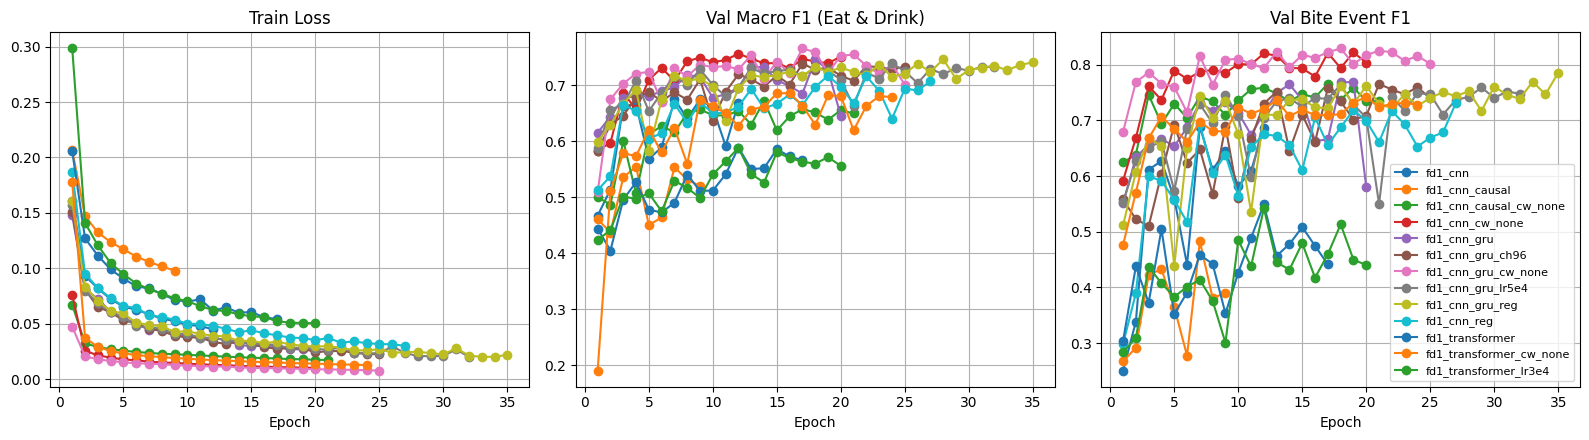

run                      best_ep  eat P  eat R  eat F1  drk F1  bite P  bite R  bite F1  bite MAE
------------------------------------------------------------------------------------------------------
fd1_cnn                        7  0.516  0.748   0.610   0.740   0.699   0.679    0.689      27.9
fd1_cnn_causal                 4  0.344  0.628   0.445   0.665   0.318   0.679    0.433     153.0
fd1_cnn_causal_cw_none        14  0.718  0.507   0.594   0.751   0.701   0.772    0.734      38.7
fd1_cnn_cw_none               12  0.783  0.601   0.680   0.833   0.889   0.761    0.820      27.4
fd1_cnn_gru                   18  0.611  0.757   0.677   0.816   0.812   0.729    0.768      22.3
fd1_cnn_gru_ch96              17  0.639  0.710   0.672   0.806   0.836   0.694    0.758      30.3
fd1_cnn_gru_cw_none           17  0.750  0.678   0.712   0.820   0.876   0.775    0.822      21.3
fd1_cnn_gru_lr5e4             24  0.581  0.768   0.661   0.817   0.789   0.712    0.749      23.1
fd1_cnn_gru_reg

In [10]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

runs_dir = Path("results/runs")
fd1_runs = sorted(
    p for p in runs_dir.iterdir()
    if (p / "history.json").exists() and (p / "metrics.json").exists()
    and "bite_count" in json.loads((p / "metrics.json").read_text()).get("validation", {})
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for run in fd1_runs:
    hist = json.loads((run / "history.json").read_text())
    epochs = [h["epoch"] for h in hist]
    axes[0].plot(epochs, [h["train_loss"] for h in hist], marker="o", label=run.name)
    axes[1].plot(epochs, [h["val_macro_f1"] for h in hist], marker="o", label=run.name)
    axes[2].plot(epochs, [h["val_bite_f1"] for h in hist], marker="o", label=run.name)

axes[0].set_title("Train Loss"); axes[0].set_xlabel("Epoch"); axes[0].grid(True)
axes[1].set_title("Val Macro F1 (Eat & Drink)"); axes[1].set_xlabel("Epoch"); axes[1].grid(True)
axes[2].set_title("Val Bite Event F1"); axes[2].set_xlabel("Epoch"); axes[2].grid(True)
axes[2].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

# Print Precision vs Recall & Bite Count MAE so we know HOW to tune!
print(f"{'run':<24} {'best_ep':>7} {'eat P':>6} {'eat R':>6} {'eat F1':>7} {'drk F1':>7} {'bite P':>7} {'bite R':>7} {'bite F1':>8} {'bite MAE':>9}")
print("-" * 102)
for run in fd1_runs:
    m = json.loads((run / "metrics.json").read_text())
    v = m["validation"]
    eat = v["sample"]["per_class"]["eating"]
    drk = v["sample"]["per_class"]["drinking"]
    bite = v["events"]["eating"]
    mae = v["bite_count"]["per_participant_error"]["mae"]
    print(f"{run.name:<24} {m['best_epoch']:>7} {eat['precision']:>6.3f} {eat['recall']:>6.3f} "
          f"{eat['f1']:>7.3f} {drk['f1']:>7.3f} {bite['precision']:>7.3f} {bite['recall']:>7.3f} "
          f"{bite['f1']:>8.3f} {mae:>9.1f}")

In [7]:
# Clean up the 2-epoch smoke test so charts stay clean
!rm -rf results/runs/fd1_smoke_test

# 1. Tune WINNER (cnn_gru): smoother LR, regularization, and slightly wider capacity
!python scripts/train/train_fd1.py --model cnn_gru --lr 5e-4 --epochs 35 --patience 8 --run-name fd1_cnn_gru_lr5e4
!python scripts/train/train_fd1.py --model cnn_gru --lr 5e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_cnn_gru_reg
!python scripts/train/train_fd1.py --model cnn_gru --channels 96 --lr 5e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_cnn_gru_ch96

# 2. Fix LIVE-DEMO model (cnn_causal): drop aggressive class weights to kill false-positive bites!
!python scripts/train/train_fd1.py --model cnn --causal --class-weight none --lr 5e-4 --dropout 0.2 --epochs 30 --patience 7 --run-name fd1_cnn_causal_cw_none

# 3. Smooth out fast watch CNN (cnn): lower LR + regularization
!python scripts/train/train_fd1.py --model cnn --lr 3e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_cnn_reg

# 4. Fairer LR + regularization for Transformer (for Q4 comparison)
!python scripts/train/train_fd1.py --model transformer --lr 3e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_transformer_lr3e4

# 5. Compare all runs & back up everything to Google Drive!
!python scripts/train/compare_fd1_runs.py
!cp -r results/ /content/drive/MyDrive/cmps364_results/


KU LEUVEN FD-I GESTURE MODEL: cnn_gru
Run:            results/runs/fd1_cnn_gru_lr5e4
Device:         cuda
Parameters:     135,107
Context:        240 samples (15.0 s)
Look-ahead:     15.0 s of future readings
Class weights:  [1.0, 10.6, 16.9]
Train windows:  42,788

epoch   1  loss 0.1576  val eat F1 0.457  drink F1 0.718  bite F1 0.553  55s  *
epoch   2  loss 0.0798  val eat F1 0.584  drink F1 0.729  bite F1 0.627  55s  *
epoch   3  loss 0.0684  val eat F1 0.599  drink F1 0.734  bite F1 0.651  56s  *
epoch   4  loss 0.0605  val eat F1 0.617  drink F1 0.799  bite F1 0.663  56s  *
epoch   5  loss 0.0563  val eat F1 0.549  drink F1 0.759  bite F1 0.573  56s
epoch   6  loss 0.0479  val eat F1 0.617  drink F1 0.757  bite F1 0.684  56s
epoch   7  loss 0.0469  val eat F1 0.658  drink F1 0.773  bite F1 0.729  55s  *
epoch   8  loss 0.0454  val eat F1 0.626  drink F1 0.777  bite F1 0.695  56s
epoch   9  loss 0.0406  val eat F1 0.656  drink F1 0.801  bite F1 0.746  56s  *
epoch  10  loss 0.041

In [9]:
# Test --class-weight none on the other 3 architectures (keep --eval-test OFF!)
!python scripts/train/train_fd1.py --model cnn_gru --class-weight none --lr 5e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_cnn_gru_cw_none
!python scripts/train/train_fd1.py --model cnn --class-weight none --lr 3e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_cnn_cw_none
!python scripts/train/train_fd1.py --model transformer --class-weight none --lr 3e-4 --dropout 0.2 --weight-decay 1e-3 --epochs 35 --patience 8 --run-name fd1_transformer_cw_none

# Compare ALL runs & back up to Google Drive!
!python scripts/train/compare_fd1_runs.py
!cp -r results/ /content/drive/MyDrive/cmps364_results/


KU LEUVEN FD-I GESTURE MODEL: cnn_gru
Run:            results/runs/fd1_cnn_gru_cw_none
Device:         cuda
Parameters:     135,107
Context:        240 samples (15.0 s)
Look-ahead:     15.0 s of future readings
Class weights:  [1.0, 1.0, 1.0]
Train windows:  42,788

epoch   1  loss 0.0474  val eat F1 0.491  drink F1 0.527  bite F1 0.679  55s  *
epoch   2  loss 0.0206  val eat F1 0.625  drink F1 0.726  bite F1 0.769  55s  *
epoch   3  loss 0.0180  val eat F1 0.644  drink F1 0.762  bite F1 0.786  56s  *
epoch   4  loss 0.0164  val eat F1 0.627  drink F1 0.815  bite F1 0.766  56s  *
epoch   5  loss 0.0153  val eat F1 0.664  drink F1 0.784  bite F1 0.760  55s  *
epoch   6  loss 0.0144  val eat F1 0.563  drink F1 0.778  bite F1 0.714  56s
epoch   7  loss 0.0140  val eat F1 0.673  drink F1 0.789  bite F1 0.816  55s  *
epoch   8  loss 0.0135  val eat F1 0.632  drink F1 0.799  bite F1 0.764  56s
epoch   9  loss 0.0128  val eat F1 0.670  drink F1 0.804  bite F1 0.809  56s  *
epoch  10  loss 0.

In [11]:
import sys
from argparse import Namespace
import torch

sys.path.insert(0, "scripts/train")
from common import RUNS_DIR, RecordingStore, load_json, load_normalization, load_windows, pick_device, save_json
from models import build_gesture_model
from train_fd1 import CACHE_DIR, NORMALIZATION_PATH, WINDOWS_PATH, evaluate

device = pick_device("auto")
mean, std = load_normalization(NORMALIZATION_PATH)
store = RecordingStore(CACHE_DIR)
test_rows = load_windows(WINDOWS_PATH, "test")

winners = [
    "fd1_cnn_gru_cw_none",
    "fd1_cnn_cw_none",
    "fd1_cnn_causal_cw_none",
    "fd1_transformer_cw_none",
]

for run_name in winners:
    run_dir = RUNS_DIR / run_name
    cfg = load_json(run_dir / "config.json")
    metrics = load_json(run_dir / "metrics.json")

    opts = {"channels": cfg["channels"], "dropout": cfg["dropout"]}
    if cfg.get("causal"):
        opts["causal"] = True
    model = build_gesture_model(cfg["model"], **opts).to(device)
    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device))
    model.eval()

    scoring_args = Namespace(
        min_event_seconds=cfg["min_event_seconds"],
        merge_gap_seconds=cfg["merge_gap_seconds"],
        bout_gap_seconds=cfg.get("bout_gap_seconds", 60.0),
    )
    metrics["test"] = evaluate(
        model, test_rows, store, mean, std, device, scoring_args,
        predictions_path=run_dir / "predictions_test.csv",
    )
    save_json(run_dir / "metrics.json", metrics)

    t = metrics["test"]
    print(f"{run_name:<26} TEST | eat F1 {t['sample']['per_class']['eating']['f1']:.3f} | "
          f"drink F1 {t['sample']['per_class']['drinking']['f1']:.3f} | "
          f"bite F1 {t['events']['eating']['f1']:.3f} | "
          f"drink ev F1 {t['events']['drinking']['f1']:.3f} | "
          f"bite MAE {t['bite_count']['per_participant_error']['mae']:.1f}")

fd1_cnn_gru_cw_none        TEST | eat F1 0.679 | drink F1 0.797 | bite F1 0.817 | drink ev F1 0.834 | bite MAE 22.0
fd1_cnn_cw_none            TEST | eat F1 0.638 | drink F1 0.807 | bite F1 0.776 | drink ev F1 0.837 | bite MAE 24.7
fd1_cnn_causal_cw_none     TEST | eat F1 0.581 | drink F1 0.728 | bite F1 0.751 | drink ev F1 0.787 | bite MAE 28.7
fd1_transformer_cw_none    TEST | eat F1 0.548 | drink F1 0.732 | bite F1 0.623 | drink ev F1 0.654 | bite MAE 46.3


In [12]:
# 1. int8 compression check (Q6) on all 4 winning models (validation + test)
!python scripts/train/quantize_fd1.py fd1_cnn_gru_cw_none --eval-test
!python scripts/train/quantize_fd1.py fd1_cnn_cw_none --eval-test
!python scripts/train/quantize_fd1.py fd1_cnn_causal_cw_none --eval-test
!python scripts/train/quantize_fd1.py fd1_transformer_cw_none --eval-test

# 2. Rebuild comparison CSV containing ALL 13 runs (validation + test where scored)
!python scripts/train/compare_fd1_runs.py

# 3. Back up EVERY single created file (all 13 runs + checkpoints + CSVs + JSONs) to Google Drive!
!mkdir -p /content/drive/MyDrive/cmps364_results
!cp -r results/ /content/drive/MyDrive/cmps364_results/
!zip -rq /content/drive/MyDrive/cmps364_fd1_all_runs.zip results/
!ls -lh /content/drive/MyDrive/cmps364_fd1_all_runs.zip

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/conv.py:101: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch._empty_affine_quantized(
INT8 CONVERSION  run fd1_cnn_gru_cw_none  model cnn_gru
Engine: qnnpack
Method: static int8 (FX graph mode, calibrated on training windows)

            size MB   ms/min  vali eat F1  bite F1  bite MAE  test eat F1  bite F1  bite MAE
float32       0.557    112.1        0.712    0.822      21.3        0.679    0.817      22.0
int8          0.314    115.9        0.710    0.816      21.0        0.679    0.815      22.3

CPU time is measured on this

In [2]:
%%bash
set -e
mkdir -p data/raw/clemson_allday

# 1. Download all 3 files directly from Clemson
curl -fLk --progress-bar -o data/raw/clemson_allday/EVENTfiles.zip \
  https://cecas.clemson.edu/tracking/ShimmerData/download/EVENTfiles.zip

curl -fLk --progress-bar -o data/raw/clemson_allday/ShimmerDemographics.xlsx \
  https://cecas.clemson.edu/tracking/ShimmerData/download/ShimmerDemographics.xlsx

curl -fLk --progress-bar -o data/raw/clemson_allday/SHMfiles.zip \
  https://cecas.clemson.edu/tracking/ShimmerData/download/SHMfiles.zip

# 2. Verify exact SHA-256 checksums from data/metadata/clemson_allday_downloads.json
sha256sum -c << 'EOF'
b69fc371e09721b9eb24a51c7438fdab18df19fa63c76bfdbeba5643ba6ac6bd  data/raw/clemson_allday/EVENTfiles.zip
b09fd84c04840666c033509004a21f5077b950f7da7d2f0cecc716337fd84664  data/raw/clemson_allday/ShimmerDemographics.xlsx
9362f8b971b2f2fd9f5ece7440910b9de9e4cd6828a4e324a1e3c8247bb5fe64  data/raw/clemson_allday/SHMfiles.zip
EOF

# 3. Preprocess, validate, and compute normalization
python scripts/data/preprocess_clemson_events.py
python scripts/data/validate_clemson_alignment.py
python scripts/data/preprocess_clemson.py
python scripts/data/validate_clemson_processed.py
python scripts/data/compute_clemson_normalization.py

# 4. Save Clemson normalization + audits to Drive immediately
mkdir -p /content/drive/MyDrive/cmps364_clemson
cp config/clemson_normalization.json /content/drive/MyDrive/cmps364_clemson/
cp results/data_audit/clemson_preprocessing_summary.json \
   results/data_audit/clemson_processed_validation.json \
   /content/drive/MyDrive/cmps364_clemson/

data/raw/clemson_allday/EVENTfiles.zip: OK
data/raw/clemson_allday/ShimmerDemographics.xlsx: OK
data/raw/clemson_allday/SHMfiles.zip: OK

CLEMSON EVENT PREPROCESSING
Source files parsed:    354
Recording IDs:          354
Recordings w/events:    354
Event rows:             1133
Event hours:            265.24
START-END log span:     5114.40 h

Missing START:          0
Missing END:            0
Malformed markers:      0
Malformed events:       0
Nonpositive events:     0
Out-of-bounds events:   0
Overlap recordings:     0
Overflow timestamps:    30

Missing demographics:  ['P2484']

Note: START-END log span is not assumed to equal usable sensor duration.

Saved:
  data/processed/clemson_allday/events.csv
  data/processed/clemson_allday/recordings.csv
  results/data_audit/clemson_events_validation.json

CLEMSON SENSOR/EVENT ALIGNMENT
Recordings:          354
Sensor recordings:   354
Events:              1133
Aligned events:      1132
Unaligned events:    1

Sensor hours:        4704.11



######################################################################## 100.0%
######################################################################## 100.0%
######################################################################## 100.0%


In [3]:
# 1. Baseline (default pos_weight=sqrt, lr=1e-3, dropout=0.3)
!python scripts/train/train_clemson.py --epochs 20 --patience 5 --run-name clemson_cnn_base

# 2. Targeted tuning (class weight, LR, regularization — keep --eval-test OFF!)
!python scripts/train/train_clemson.py --pos-weight none --epochs 25 --patience 6 --run-name clemson_cnn_pw_none
!python scripts/train/train_clemson.py --pos-weight 2.0 --lr 5e-4 --epochs 25 --patience 6 --run-name clemson_cnn_pw2_lr5e4
!python scripts/train/train_clemson.py --pos-weight sqrt --lr 5e-4 --dropout 0.4 --weight-decay 1e-3 --epochs 25 --patience 6 --run-name clemson_cnn_reg

# 3. Back up ALL Clemson runs + normalization + audits to Google Drive!
!cp -r results/runs/clemson_* /content/drive/MyDrive/cmps364_clemson/
!zip -rq /content/drive/MyDrive/cmps364_clemson_all_runs.zip \
    results/runs/clemson_* \
    config/clemson_normalization.json \
    results/data_audit/clemson_processed_validation.json \
    results/data_audit/clemson_preprocessing_summary.json
!ls -lh /content/drive/MyDrive/cmps364_clemson_all_runs.zip


CLEMSON ALL-DAY EPISODE CNN
Run:           results/runs/clemson_cnn_base
Device:        cuda
Parameters:    57,633
Window/stride: 6 / 3 min
pos_weight:    4.08
Train windows: 65,385

epoch   1  loss 0.4145  val loss 0.1688  val window F1 0.534  156s  *
epoch   2  loss 0.3773  val loss 0.1952  val window F1 0.571  83s  *
epoch   3  loss 0.3628  val loss 0.1896  val window F1 0.587  83s  *
epoch   4  loss 0.3506  val loss 0.1535  val window F1 0.588  83s  *
epoch   5  loss 0.3371  val loss 0.2285  val window F1 0.560  83s
epoch   6  loss 0.3249  val loss 0.1639  val window F1 0.599  81s  *
epoch   7  loss 0.3119  val loss 0.2703  val window F1 0.466  81s
epoch   8  loss 0.3027  val loss 0.2067  val window F1 0.550  80s
epoch   9  loss 0.2899  val loss 0.1498  val window F1 0.598  81s
epoch  10  loss 0.2765  val loss 0.2901  val window F1 0.442  83s
epoch  11  loss 0.2630  val loss 0.1991  val window F1 0.547  84s
No improvement for 5 epochs, stopping.

Best epoch: 6
Thresholds (from val

In [4]:
!python scripts/train/train_clemson.py \
    --pos-weight none --lr 5e-4 --dropout 0.4 --weight-decay 1e-3 \
    --epochs 25 --patience 6 --run-name clemson_cnn_pw_none_reg


CLEMSON ALL-DAY EPISODE CNN
Run:           results/runs/clemson_cnn_pw_none_reg
Device:        cuda
Parameters:    57,633
Window/stride: 6 / 3 min
pos_weight:    1.00
Train windows: 65,385

epoch   1  loss 0.1782  val loss 0.1440  val window F1 0.436  94s  *
epoch   2  loss 0.1522  val loss 0.1396  val window F1 0.451  83s  *
epoch   3  loss 0.1471  val loss 0.1434  val window F1 0.541  83s  *
epoch   4  loss 0.1436  val loss 0.1505  val window F1 0.338  83s
epoch   5  loss 0.1393  val loss 0.1378  val window F1 0.497  84s
epoch   6  loss 0.1359  val loss 0.1377  val window F1 0.504  83s
epoch   7  loss 0.1320  val loss 0.1404  val window F1 0.503  83s
epoch   8  loss 0.1292  val loss 0.1362  val window F1 0.474  83s
epoch   9  loss 0.1267  val loss 0.1449  val window F1 0.462  84s
No improvement for 6 epochs, stopping.

Best epoch: 3
Thresholds (from validation): start 0.4, end 0.1

VALIDATION
  window F1          0.541
  episodes found     108/174 (62.1%)
  false alarms       28 (0.

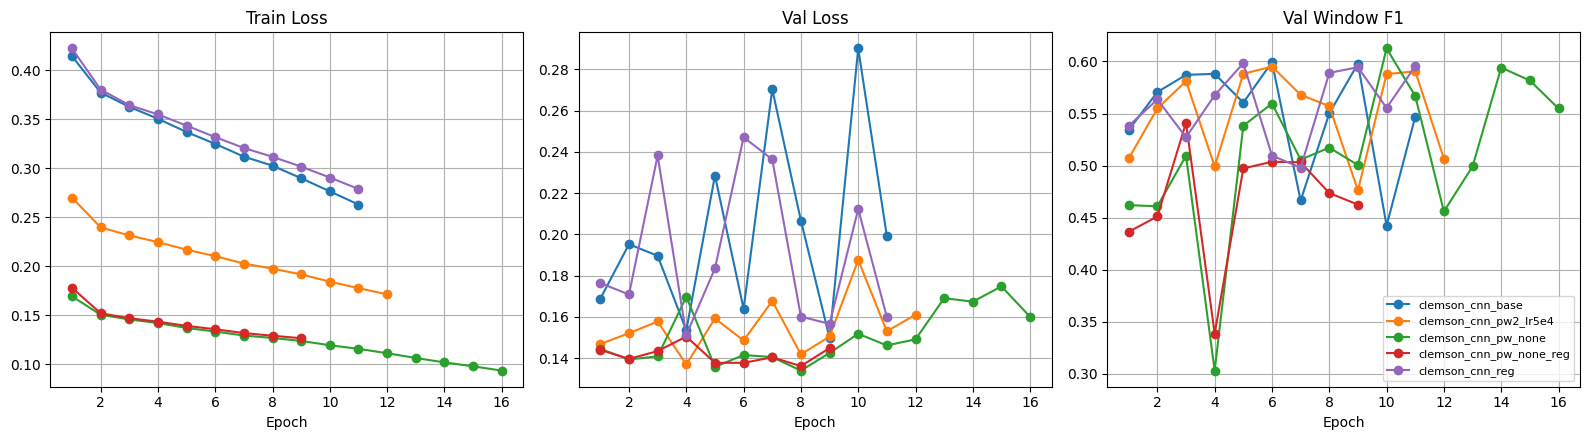

run                         ep  winF1   found  FA/day   epF1  timeF1  mealMAE  minMAE   st/en(m)
--------------------------------------------------------------------------------------------------
clemson_cnn_base             6  0.599   77.6%    1.76  0.748   0.539     1.00    31.8  4.0/6.9 
clemson_cnn_pw2_lr5e4        6  0.595   74.1%    1.49  0.744   0.575     1.08    25.1  3.3/5.4 
clemson_cnn_pw_none         10  0.613   74.1%    1.22  0.761   0.586     0.92    22.2  3.1/5.6 
clemson_cnn_pw_none_reg      3  0.541   62.1%    0.95  0.697   0.591     1.28    19.5  2.4/4.3 
clemson_cnn_reg              5  0.598   77.6%    1.25  0.780   0.502     0.94    42.6  3.7/11.1


In [5]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

runs_dir = Path("results/runs")
clemson_runs = sorted(
    p for p in runs_dir.glob("clemson_*")
    if (p / "history.json").exists() and (p / "metrics.json").exists()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for run in clemson_runs:
    hist = json.loads((run / "history.json").read_text())
    epochs = [h["epoch"] for h in hist]
    axes[0].plot(epochs, [h["train_loss"] for h in hist], marker="o", label=run.name)
    axes[1].plot(epochs, [h["val_loss"] for h in hist], marker="o", label=run.name)
    axes[2].plot(epochs, [h["val_window_f1"] for h in hist], marker="o", label=run.name)

axes[0].set_title("Train Loss"); axes[0].set_xlabel("Epoch"); axes[0].grid(True)
axes[1].set_title("Val Loss"); axes[1].set_xlabel("Epoch"); axes[1].grid(True)
axes[2].set_title("Val Window F1"); axes[2].set_xlabel("Epoch"); axes[2].grid(True)
axes[2].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'run':<26} {'ep':>3} {'winF1':>6} {'found':>7} {'FA/day':>7} {'epF1':>6} {'timeF1':>7} {'mealMAE':>8} {'minMAE':>7} {'st/en(m)':>10}")
print("-" * 98)
for run in clemson_runs:
    m = json.loads((run / "metrics.json").read_text())
    v = m["validation"]
    ep, tot = v["episodes"], v["daily_totals"]
    st = ep["mean_start_error_minutes"] or 0.0
    en = ep["mean_end_error_minutes"] or 0.0
    print(f"{run.name:<26} {m['best_epoch']:>3} {v['windows']['f1']:>6.3f} "
          f"{ep['true_positive_rate']*100:>6.1f}% {ep['false_alarms_per_day']:>7.2f} "
          f"{ep['f1']:>6.3f} {v['time']['f1']:>7.3f} "
          f"{tot['meals_per_day_mae']:>8.2f} {tot['eating_minutes_per_day_mae']:>7.1f} "
          f"{st:>4.1f}/{en:<4.1f}")

In [6]:
import sys
from argparse import Namespace
import torch

# Put your 1 winning Clemson run name here (compare D3 vs clemson_cnn_pw_none vs clemson_cnn_reg):
WINNER = "clemson_cnn_pw_none"

sys.path.insert(0, "scripts/train")
from common import RUNS_DIR, RecordingStore, load_json, load_normalization, load_windows, pick_device, save_json
from models import EpisodeCNN
from train_clemson import (
    CACHE_DIR, NORMALIZATION_PATH, WINDOWS_PATH,
    episode_scores, group_by_recording, window_probabilities, window_scores,
)

device = pick_device("auto")
mean, std = load_normalization(NORMALIZATION_PATH)
store = RecordingStore(CACHE_DIR)
test_rows = load_windows(WINDOWS_PATH, "test")

run_dir = RUNS_DIR / WINNER
cfg = load_json(run_dir / "config.json")
metrics = load_json(run_dir / "metrics.json")

model = EpisodeCNN(dropout=cfg["dropout"]).to(device)
model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device))
model.eval()

test_preds = window_probabilities(
    model, group_by_recording(test_rows), store, mean, std, device, cfg["batch_size"]
)
scoring_args = Namespace(
    merge_gap_minutes=cfg["merge_gap_minutes"],
    min_episode_minutes=cfg["min_episode_minutes"],
)
val_t = metrics["validation"]
metrics["test"] = {
    "windows": window_scores(test_preds),
    **episode_scores(
        test_preds, cfg["stride_samples"],
        val_t["start_threshold"], val_t["end_threshold"],
        scoring_args, meals_path=run_dir / "meals_test.csv",
    ),
}
save_json(run_dir / "metrics.json", metrics)

t = metrics["test"]
ep, tot = t["episodes"], t["daily_totals"]
print(f"TEST ({WINNER}) | thresholds start={val_t['start_threshold']} end={val_t['end_threshold']}")
print(f"  window F1:          {t['windows']['f1']:.3f}")
print(f"  episodes found:     {ep['tp']}/{ep['tp']+ep['fn']} ({ep['true_positive_rate']:.1%})")
print(f"  false alarms:       {ep['fp']} ({ep['false_alarms_per_hour']:.3f}/h, {ep['false_alarms_per_day']:.2f}/day)")
print(f"  episode F1:         {ep['f1']:.3f}  |  time F1: {t['time']['f1']:.3f}")
print(f"  start/end err (m):  {ep['mean_start_error_minutes']:.2f} / {ep['mean_end_error_minutes']:.2f}")
print(f"  meals/day:          true {tot['mean_true_meals_per_day']:.2f}, pred {tot['mean_predicted_meals_per_day']:.2f} (MAE {tot['meals_per_day_mae']:.2f})")
print(f"  eating min/day:     true {tot['mean_true_eating_minutes_per_day']:.1f}, pred {tot['mean_predicted_eating_minutes_per_day']:.1f} (MAE {tot['eating_minutes_per_day_mae']:.1f})")

TEST (clemson_cnn_pw_none) | thresholds start=0.45 end=0.1
  window F1:          0.551
  episodes found:     118/165 (71.5%)
  false alarms:       57 (0.081/h, 1.94/day)
  episode F1:         0.694  |  time F1: 0.551
  start/end err (m):  4.09 / 6.55
  meals/day:          true 3.11, pred 3.30 (MAE 1.02)
  eating min/day:     true 47.9, pred 57.6 (MAE 25.9)


In [8]:
%%bash
set -e
python scripts/train/analyze_clemson_meals.py clemson_cnn_pw_none --split validation
python scripts/train/analyze_clemson_meals.py clemson_cnn_pw_none --split test

cp -r results/runs/clemson_* /content/drive/MyDrive/cmps364_clemson/
rm -f /content/drive/MyDrive/cmps364_clemson_all_runs.zip
zip -rq /content/drive/MyDrive/cmps364_clemson_all_runs.zip \
    results/runs/clemson_* \
    config/clemson_normalization.json \
    results/data_audit/clemson_processed_validation.json \
    results/data_audit/clemson_preprocessing_summary.json
ls -lh /content/drive/MyDrive/cmps364_clemson_all_runs.zip

CLEMSON MEAL BREAKDOWN  run clemson_cnn_pw_none  split validation
Events matched to labels: 174 of 174
Recordings with demographics: 53 of 53

By meal type
------------------------------------------------------------------------
dinner                        n 52  found 0.88  start err 3.87  end err 6.40
lunch                         n 44  found 0.75  start err 2.93  end err 5.56
breakfast                     n 39  found 0.74  start err 2.02  end err 5.17
snack                         n 37  found 0.51  start err 3.33  end err 5.04
other                         n 2  found 1.00  start err 1.65  end err 1.38

By duration
------------------------------------------------------------------------
5-15 min                      n 84  found 0.80  start err 2.68  end err 4.81
15-30 min                     n 43  found 0.84  start err 3.32  end err 6.36
under 5 min                   n 34  found 0.47  start err 2.02  end err 4.22
30+ min                       n 13  found 0.77  start err 6.84  end er

# For Q5

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!nvidia-smi
!rm -rf /content/364-project
!git clone -b q5-personalization https://github.com/jesss77/364-project.git /content/364-project
%cd /content/364-project

Mounted at /content/drive
Fri Nov 27 21:54:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

In [3]:
!python scripts/data/download_data.py --dataset kuleuven --file FD-I.zip
!python scripts/data/preprocess_fd1.py
!python scripts/data/validate_fd1_processed.py

Downloading: FD-I.zip
Source: https://rdr.kuleuven.be/api/access/datafile/160779
Destination: data/raw/kuleuven/FD-I.zip
Progress: 10% (261.00 MB / 2.54 GB)
Progress: 20% (521.00 MB / 2.54 GB)
Progress: 30% (782.00 MB / 2.54 GB)
Progress: 40% (1.02 GB / 2.54 GB)
Progress: 50% (1.27 GB / 2.54 GB)
Progress: 60% (1.53 GB / 2.54 GB)
Progress: 70% (1.78 GB / 2.54 GB)
Progress: 80% (2.04 GB / 2.54 GB)
Progress: 90% (2.29 GB / 2.54 GB)
Progress: 100% (2.54 GB / 2.54 GB)
MD5 verified: e5adb4c6f3caa8f52c215658228917dd
Saved: data/raw/kuleuven/FD-I.zip

KU LEUVEN FD-I PREPROCESSING
Raw rate:        64 Hz
Output rate:     16 Hz
Window:          60 s (960 samples)
Stride:          30 s (480 samples)
Wrists:          separate

Some FD-I files are missing.
Extracting them from FD-I.zip...
Extraction complete.

PROCESSING WRIST L
------------------------------------------------------------
Loading X_L.pkl...
Loaded X_L.pkl
Loading Y_L.pkl...
Loaded Y_L.pkl
L participant 00 [train     ] 1,984,366 → 49

In [4]:
import shutil
from pathlib import Path

drive_q5 = Path("/content/drive/MyDrive/cmps364_q5")
drive_q5.mkdir(parents=True, exist_ok=True)

# Copy Fold 0 (already in repo from Ali) to Drive too so all 7 live together
fold0_src = Path("results/runs/fd1_personalization_cnn_fold0")
if fold0_src.exists() and not (drive_q5 / fold0_src.name).exists():
    shutil.copytree(fold0_src, drive_q5 / fold0_src.name)

for fold in [1, 2, 3, 4, 5, 6]:
    run_name = f"fd1_personalization_cnn_fold{fold}"
    drive_dst = drive_q5 / run_name
    if (drive_dst / "personalization.json").exists():
        print(f"Fold {fold} already done in Drive, skipping.")
        continue

    print(f"\n========== RUNNING FOLD {fold} ==========")
    !python scripts/train/personalize_fd1.py --model cnn --folds {fold} --run-name {run_name}

    local_src = Path("results/runs") / run_name
    if (local_src / "personalization.json").exists():
        if drive_dst.exists():
            shutil.rmtree(drive_dst)
        shutil.copytree(local_src, drive_dst)
        print(f"Backed up Fold {fold} to Google Drive.")


========== RUNNING FOLD 1 ==========

Q5 NEW-USER EXPERIMENT
Run:     results/runs/fd1_personalization_cnn_fold1
Folds:   FD1_7_fold_id_list.zip, running [1]
Budgets: [1, 2, 5] min of the person's labeled data; modes ['head', 'all']

fold 1: base model trained on 50,330 windows in 459s, held out [0, 4, 14, 17, 29]
  participant 0: base eat F1 0.612 | head 1m 0.648 | all 1m 0.658 | head 2m 0.621 | all 2m 0.638 | head 5m 0.584 | all 5m 0.611
  participant 4: base eat F1 0.459 | head 1m 0.609 | all 1m 0.653 | head 2m 0.626 | all 2m 0.688 | head 5m 0.588 | all 5m 0.630
  participant 14: base eat F1 0.658 | head 1m 0.717 | all 1m 0.702 | head 2m 0.691 | all 2m 0.702 | head 5m 0.623 | all 5m 0.610
  participant 17: base eat F1 0.820 | head 1m 0.829 | all 1m 0.808 | head 2m 0.822 | all 2m 0.805 | head 5m 0.703 | all 5m 0.697
  participant 29: base eat F1 0.726 | head 1m 0.675 | all 1m 0.594 | head 2m 0.729 | all 2m 0.688 | head 5m 0.723 | all 5m 0.717

AVERAGE OVER 5 HELD-OUT PARTICIPANTS
va

In [5]:
import json, shutil
from pathlib import Path
import numpy as np

drive_q5 = Path("/content/drive/MyDrive/cmps364_q5")
all_entries = []
fold0_cfg = None

for fold in range(7):
    run_name = f"fd1_personalization_cnn_fold{fold}"
    src = drive_q5 / run_name
    local = Path("results/runs") / run_name
    if not (local / "personalization.json").exists() and (src / "personalization.json").exists():
        shutil.copytree(src, local, dirs_exist_ok=True)

    data = json.loads((local / "personalization.json").read_text(encoding="utf-8"))
    all_entries.extend(data["per_participant"])
    if fold == 0:
        fold0_cfg = json.loads((local / "config.json").read_text(encoding="utf-8"))

all_entries.sort(key=lambda e: (e["fold"], e["participant_id"]))
variants = ["base", "head_1min", "all_1min", "head_2min", "all_2min", "head_5min", "all_5min"]
averages = {
    v: {
        k: float(np.mean([e[v][k] for e in all_entries]))
        for k in ("eating_f1", "drinking_f1", "bite_f1", "bite_count_error")
    }
    for v in variants
}

merged_dir = Path("results/runs/fd1_personalization_cnn_7fold")
merged_dir.mkdir(parents=True, exist_ok=True)
(merged_dir / "personalization.json").write_text(
    json.dumps({"participants": len(all_entries), "averages": averages, "per_participant": all_entries}, indent=2),
    encoding="utf-8",
)
if fold0_cfg:
    fold0_cfg["run_name"] = "fd1_personalization_cnn_7fold"
    (merged_dir / "config.json").write_text(json.dumps(fold0_cfg, indent=2), encoding="utf-8")

# Save merged run + zip all Q5 folders to Drive
shutil.copytree(merged_dir, drive_q5 / merged_dir.name, dirs_exist_ok=True)
!zip -rq /content/drive/MyDrive/cmps364_q5_all_folds.zip results/runs/fd1_personalization_cnn_fold* results/runs/fd1_personalization_cnn_7fold

print(f"\nCOMPLETE 7-FOLD Q5 AVERAGE OVER {len(all_entries)} HELD-OUT PARTICIPANTS")
print(f"{'variant':<12} {'eat F1':>8} {'drink F1':>9} {'bite F1':>8} {'bite MAE':>9}")
print("-" * 50)
for v, s in averages.items():
    print(f"{v:<12} {s['eating_f1']:>8.3f} {s['drinking_f1']:>9.3f} {s['bite_f1']:>8.3f} {s['bite_count_error']:>9.1f}")
!ls -lh /content/drive/MyDrive/cmps364_q5_all_folds.zip


COMPLETE 7-FOLD Q5 AVERAGE OVER 34 HELD-OUT PARTICIPANTS
variant        eat F1  drink F1  bite F1  bite MAE
--------------------------------------------------
base            0.670     0.810    0.791      16.2
head_1min       0.680     0.755    0.771      22.6
all_1min        0.674     0.790    0.776      32.7
head_2min       0.677     0.759    0.756      26.3
all_2min        0.671     0.798    0.759      34.1
head_5min       0.660     0.647    0.708      48.8
all_5min        0.654     0.741    0.738      26.8
-rw------- 1 root root 32K Nov 27 22:49 /content/drive/MyDrive/cmps364_q5_all_folds.zip
